# 08_01 — Virtual diagnostic: comparing models

Same test as notebook 08 (per segment, BCM lost at `CUT`: train on the shots before, infer every later shot from its
own `X`), with more models, and the model for each segment **chosen without looking at the test shots**:

1. split the training part again: the last `VAL_FRACTION` of it is a **validation** block
2. fit every candidate on the shots before the validation block, score it on the validation block
3. refit the best candidate on the whole training part and score it once on the test shots (after the cut)

Candidates:
- **Ridge** — linear (notebook 08); **Huber** — linear but robust to outliers
- **HGB** — gradient-boosted trees, regularised
- **Ridge + HGB residual** — linear fit, then trees on what it misses (keeps the linear extrapolation)
- **average Ridge & HGB**
- each also trained on **only the last `W` shots** before the end of its training data: the relation between the
  instruments and the BCM drifts, so recent shots can be a better calibration than the whole history

Two scores on the shots after the cut, both relative to the mean charge:
- **per shot** — RMSE of every shot
- **trend** — RMSE between the 51-shot rolling means of inferred and measured charge (how well the drift is followed)

Shots below 20% of the training median (no beam / BCM glitch) are left out of training, but kept in the scores.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"
OUT = REPO / "results" / "virtual_diagnostic"
OUT.mkdir(parents=True, exist_ok=True)

CUT = 0.7            # BCM lost after this fraction of each segment
VAL_FRACTION = 0.2   # last part of the training shots used to choose the model
WINDOWS = [None, 4000, 2000, 1000]   # train on all shots (None) or only the last W before the end of the training data
SELECT_BY = "per shot"               # or "trend"
MIN_VALID = 500
SMOOTH = 51
NO_BEAM = 0.2        # training shots below this fraction of the training median are not learned from

INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"
BASE, PICK = "#2a78d6", "#eb6834"   # Ridge (notebook 08), validation-selected model

manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]
segments = {}
for info in manifest["segments"]:
    z = np.load(DATASETS / info["file"])
    if z["valid"].sum() >= MIN_VALID:
        segments[info["segment"]] = {"X": z["X"], "y": z["y"], "valid": z["valid"], "run": info["run"]}
print(f"{len(segments)} segments: {list(segments)} | {len(FEATURES)} features")

7 segments: [0, 1, 3, 4, 5, 6, 7] | 16 features


## Candidates

In [2]:
class RidgePlusTrees(BaseEstimator, RegressorMixin):
    """Linear fit first, then gradient-boosted trees on its residual."""

    def __init__(self, linear, trees):
        self.linear, self.trees = linear, trees

    def fit(self, X, y):
        self.linear_ = clone(self.linear).fit(X, y)
        self.trees_ = clone(self.trees).fit(X, y - self.linear_.predict(X))
        return self

    def predict(self, X):
        return self.linear_.predict(X) + self.trees_.predict(X)


def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))


def huber():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), HuberRegressor(alpha=1e-3, max_iter=1000))


def hgb():
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=50,
                                         l2_regularization=1.0, random_state=0)


ESTIMATORS = {
    "Ridge": ridge,
    "Huber": huber,
    "HGB": hgb,
    "Ridge + HGB residual": lambda: RidgePlusTrees(ridge(), hgb()),
}
AVERAGES = {"average Ridge & HGB": ("Ridge", "HGB")}   # mean of two candidates' predictions


def window_name(w):
    return "all" if w is None else f"last {w}"


CANDIDATES = [f"{m} | {window_name(w)}" for m in [*ESTIMATORS, *AVERAGES] for w in WINDOWS]
print(len(CANDIDATES), "candidates")

20 candidates


In [3]:
def smooth(a):
    return pd.Series(a).rolling(SMOOTH, center=True, min_periods=1).mean().to_numpy()


def scores(y, pred):
    return {"per shot": np.sqrt(np.mean((y - pred) ** 2)) / y.mean(),
            "trend": np.sqrt(np.mean((smooth(y) - smooth(pred)) ** 2)) / y.mean()}


def fit_all(s, train, end_row, target):
    """Fit every candidate on `train` shots (window counted back from end_row), predict the `target` shots."""
    X, y = s["X"], s["y"]
    rows = np.arange(len(y))
    train = train & (y > NO_BEAM * np.median(y[train]))
    preds = {}
    for w in WINDOWS:
        tw = train & (rows >= (end_row - w if w else 0))
        for name, make in ESTIMATORS.items():
            preds[f"{name} | {window_name(w)}"] = make().fit(X[tw], y[tw]).predict(X[target])
        for name, (a, b) in AVERAGES.items():
            preds[f"{name} | {window_name(w)}"] = (preds[f"{a} | {window_name(w)}"] + preds[f"{b} | {window_name(w)}"]) / 2
    return preds


val_scores, test_scores, test_preds, splits = {}, {}, {}, {}
for k, s in segments.items():
    n = len(s["y"])
    rows = np.arange(n)
    cut_row = int(CUT * n)
    val_row = int((1 - VAL_FRACTION) * cut_row)
    fit_part = s["valid"] & (rows < val_row)
    val = s["valid"] & (rows >= val_row) & (rows < cut_row)
    train = s["valid"] & (rows < cut_row)
    test = s["valid"] & (rows >= cut_row)

    pv = fit_all(s, fit_part, val_row, val)
    val_scores[k] = pd.DataFrame({c: scores(s["y"][val], p) for c, p in pv.items()}).T
    pt = fit_all(s, train, cut_row, test)
    test_scores[k] = pd.DataFrame({c: scores(s["y"][test], p) for c, p in pt.items()}).T
    pt["BCM frozen at cut"] = np.full(test.sum(), s["y"][train][-1])
    test_preds[k] = pt
    splits[k] = {"cut_row": cut_row, "val_row": val_row, "test": test}
    print(f"segment {k}: fit {fit_part.sum()}, validation {val.sum()}, train {train.sum()}, test {test.sum()} shots")

segment 0: fit 2587, validation 639, train 3226, test 1411 shots


segment 1: fit 8571, validation 2441, train 11012, test 5646 shots


segment 3: fit 3017, validation 734, train 3751, test 1676 shots


segment 4: fit 2146, validation 543, train 2689, test 1166 shots


segment 5: fit 8984, validation 2596, train 11580, test 5863 shots


segment 6: fit 1767, validation 437, train 2204, test 933 shots


segment 7: fit 993, validation 250, train 1243, test 537 shots


## Results

- **Ridge (08)** — Ridge on all training shots, as in notebook 08
- **chosen on validation** — the candidate with the best validation score, scored on the test shots (honest)
- **best on test** — the best candidate looking at the test shots: optimistic, only to show the ceiling of this list

In [4]:
BASELINE = "Ridge | all"
rows = []
for k in segments:
    chosen = val_scores[k][SELECT_BY].idxmin()
    frozen = scores(segments[k]["y"][splits[k]["test"]], test_preds[k]["BCM frozen at cut"])
    for metric in ["per shot", "trend"]:
        rows.append({"segment": k, "metric": metric, "BCM frozen at cut": frozen[metric],
                     "Ridge (08)": test_scores[k].loc[BASELINE, metric],
                     "chosen on validation": test_scores[k].loc[chosen, metric],
                     "best on test (optimistic)": test_scores[k][metric].min(),
                     "chosen model": chosen})
results = pd.DataFrame(rows).set_index(["metric", "segment"])
num = results.columns.drop("chosen model")
mean = results.groupby(level="metric")[num].mean().assign(**{"chosen model": "— mean —"})
mean.index = pd.MultiIndex.from_tuples([(m, "mean") for m in mean.index], names=results.index.names)
table = pd.concat([results, mean]).sort_index(level="metric", sort_remaining=False)
table.style.format({c: "{:.1%}" for c in num}).set_caption(f"RMSE / mean charge on the shots after the cut (model chosen by '{SELECT_BY}')")

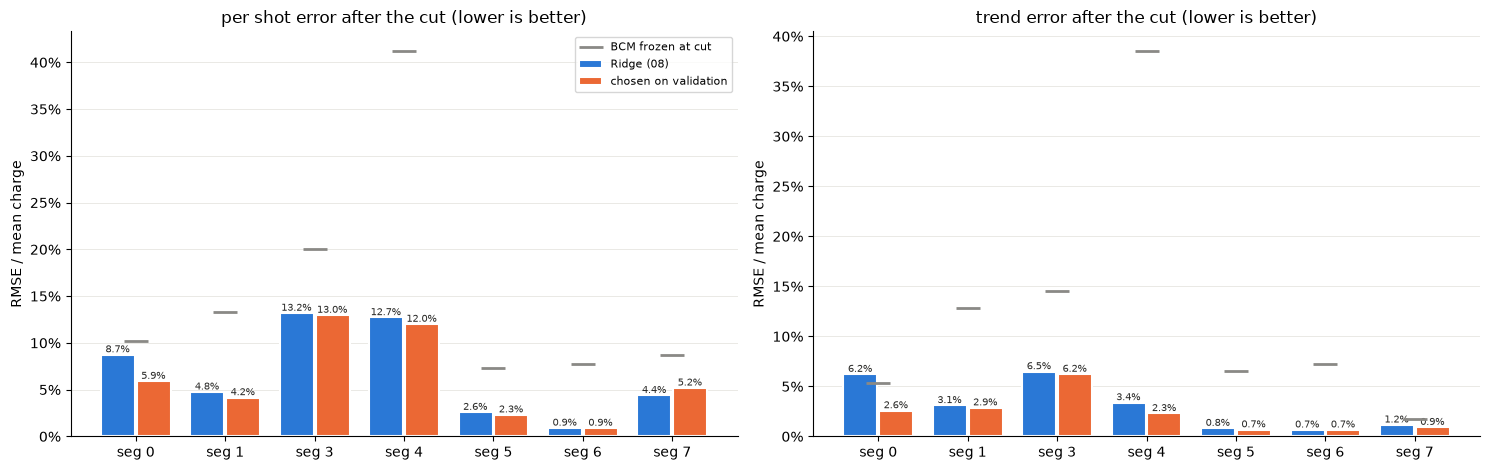

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=False)
seg_labels = [f"seg {k}" for k in segments]
x = np.arange(len(segments))
for ax, metric in zip(axes, ["per shot", "trend"]):
    r = results.xs(metric, level="metric")
    for dx, col, color in [(-0.2, "Ridge (08)", BASE), (0.2, "chosen on validation", PICK)]:
        ax.bar(x + dx, r[col], width=0.38, color=color, label=col, edgecolor="white", linewidth=1.5)
        for xi, v in zip(x + dx, r[col]):
            ax.text(xi, v, f"{v:.1%}", ha="center", va="bottom", fontsize=7, color=INK)
    ax.scatter(x, r["BCM frozen at cut"], marker="_", s=300, color=MUTED, linewidths=2, label="BCM frozen at cut", zorder=3)
    ax.set_xticks(x, seg_labels)
    ax.set(title=f"{metric} error after the cut (lower is better)", ylabel="RMSE / mean charge")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "models_comparison.png", dpi=130, bbox_inches="tight")

## All candidates on the test shots (the box marks the one chosen on validation)

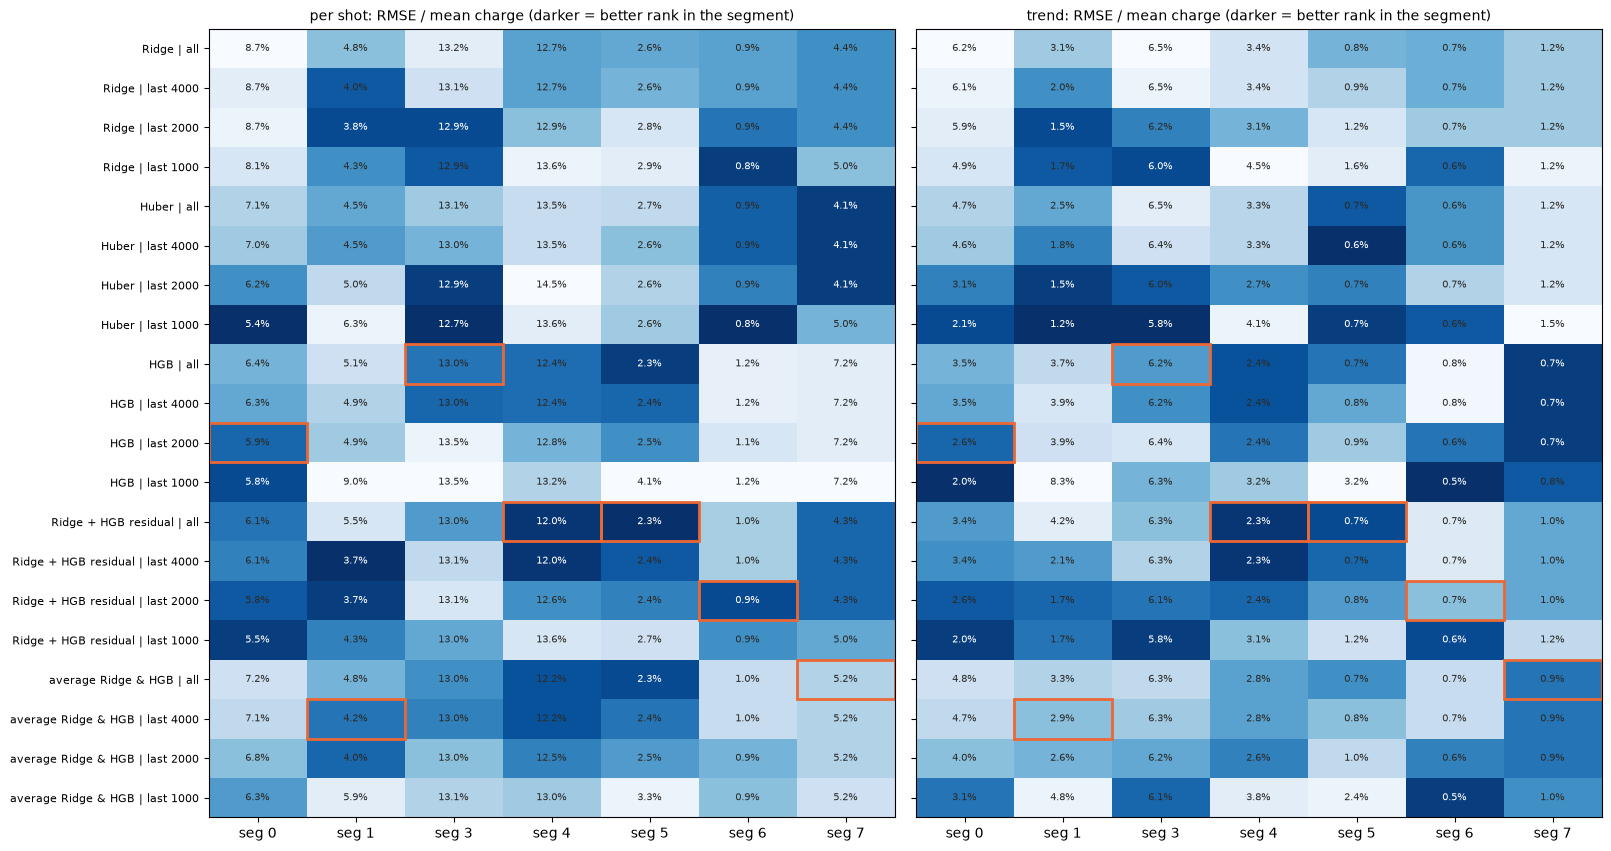

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 0.32 * len(CANDIDATES) + 2), layout="constrained")
for ax, metric in zip(axes, ["per shot", "trend"]):
    table = pd.DataFrame({k: test_scores[k][metric] for k in segments}).loc[CANDIDATES]
    rank = table.rank(axis=0)       # colour by rank within each segment: segments have very different error levels
    im = ax.imshow(rank, cmap="Blues_r", aspect="auto")
    for (i, j), v in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7, color="white" if rank.iloc[i, j] <= 3 else INK)
    for j, k in enumerate(segments):
        i = CANDIDATES.index(val_scores[k][SELECT_BY].idxmin())
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=PICK, lw=2))
    ax.set_xticks(range(len(segments)), seg_labels)
    ax.set_yticks(range(len(CANDIDATES)), CANDIDATES if ax is axes[0] else [], fontsize=8)
    ax.set_title(f"{metric}: RMSE / mean charge (darker = better rank in the segment)", fontsize=10)
fig.savefig(OUT / "models_all_candidates.png", dpi=130, bbox_inches="tight");

## Chosen model vs Ridge (08), after the cut

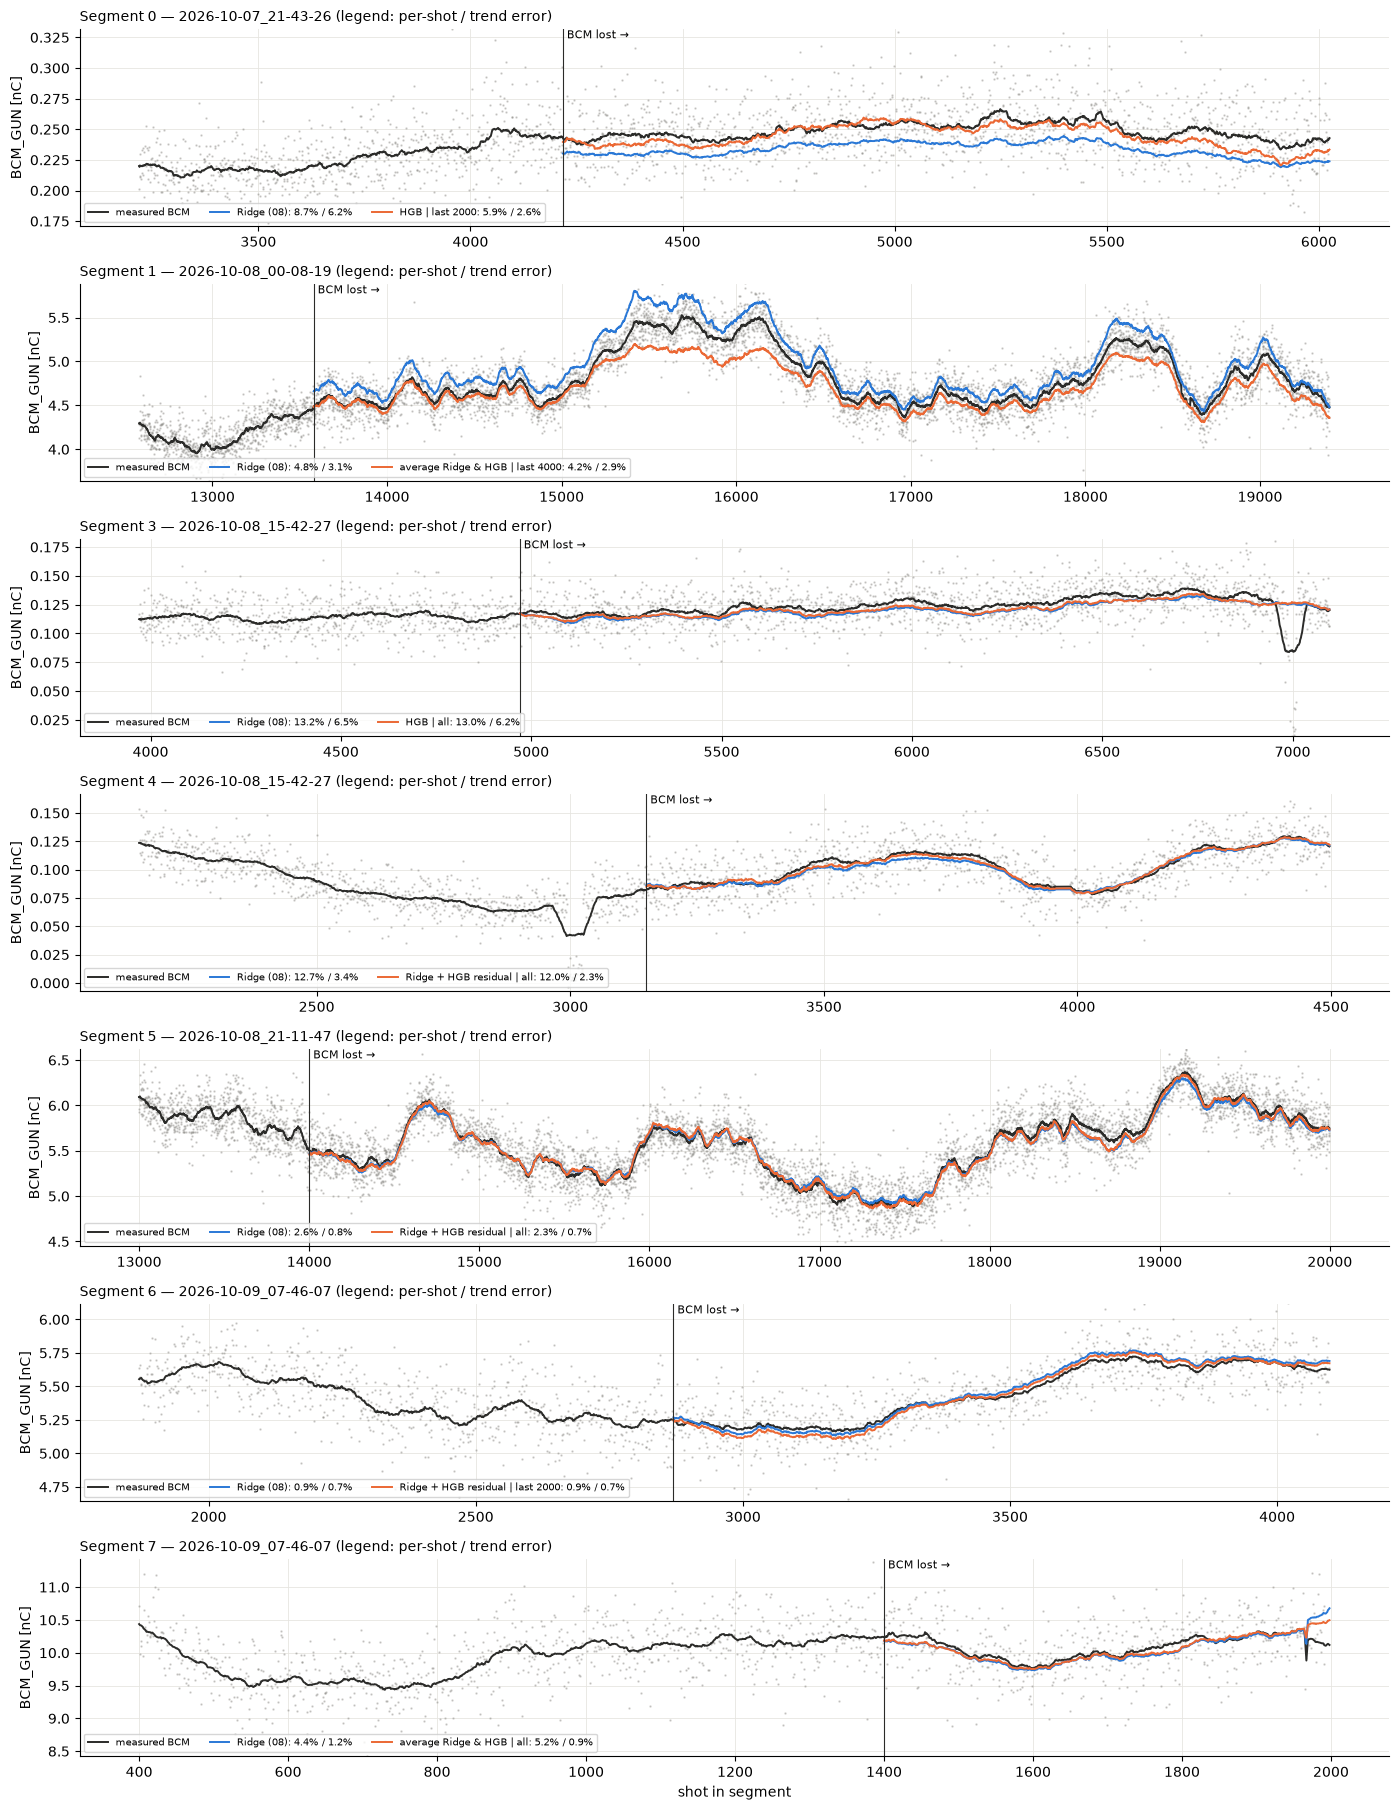

In [7]:
fig, axes = plt.subplots(len(segments), 1, figsize=(14, 2.6 * len(segments)), squeeze=False)
for ax, (k, s) in zip(axes[:, 0], segments.items()):
    sp, pt = splits[k], test_preds[k]
    shot = np.arange(len(s["y"]))
    v = s["valid"]
    start = max(sp["cut_row"] - 1000, 0)
    show = v & (shot >= start)
    ax.plot(shot[show], s["y"][show], ".", ms=1.5, color=MUTED, alpha=0.35)
    ax.plot(shot[show], smooth(s["y"][show]), color=INK, lw=1.4, label="measured BCM")
    chosen = results.loc[("per shot" if SELECT_BY == "per shot" else "trend", k), "chosen model"]
    t = sp["test"]
    ax.plot(shot[t], smooth(pt[BASELINE]), color=BASE, lw=1.4,
            label=f"Ridge (08): {test_scores[k].loc[BASELINE, 'per shot']:.1%} / {test_scores[k].loc[BASELINE, 'trend']:.1%}")
    ax.plot(shot[t], smooth(pt[chosen]), color=PICK, lw=1.4,
            label=f"{chosen}: {test_scores[k].loc[chosen, 'per shot']:.1%} / {test_scores[k].loc[chosen, 'trend']:.1%}")
    ax.axvline(sp["cut_row"], color=INK, lw=0.8)
    ax.text(sp["cut_row"], 1.0, " BCM lost →", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
    lo, hi = np.percentile(s["y"][show], [0.5, 99.5])
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
    ax.set_title(f"Segment {k} — {s['run'].removeprefix('acquisition_')} (legend: per-shot / trend error)", fontsize=10, loc="left")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.legend(fontsize=7, loc="lower left", ncol=3)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[-1, 0].set_xlabel("shot in segment")
fig.tight_layout()
fig.savefig(OUT / "models_timeseries.png", dpi=130, bbox_inches="tight")

## How low can the per-shot error go?

The per-shot error barely changes between models. A rough check of how much of each shot's charge is predictable at all:
the BCM itself fluctuates from shot to shot (detrended std below). If the residual of the best model is close to that,
the rest is shot-to-shot noise that the features do not see (BCM measurement noise and/or real jitter not visible in `X`).

In [8]:
floor = {}
for k, s in segments.items():
    t = splits[k]["test"]
    y = s["y"][t]
    chosen = results.loc[(SELECT_BY, k), "chosen model"]
    resid = y - test_preds[k][chosen]
    floor[k] = {"BCM shot-to-shot std / mean": np.std(y - smooth(y)) / y.mean(),
                "residual of chosen model / mean": np.std(resid - smooth(resid)) / y.mean(),
                "explained shot-to-shot variance": 1 - np.var(resid - smooth(resid)) / np.var(y - smooth(y))}
pd.DataFrame(floor).T.style.format("{:.1%}")

,BCM shot-to-shot std / mean,residual of chosen model / mean,explained shot-to-shot variance
0,8.7%,5.3%,63.0%
1,3.6%,3.0%,30.8%
3,13.3%,10.9%,33.2%
4,14.5%,11.8%,34.4%
5,3.1%,2.2%,50.1%
6,2.7%,0.6%,95.4%
7,8.5%,5.1%,64.4%
